## 1. Configurations

### 1-1. Import libraries

In [1]:
from    typing      import  Callable, Hashable, Sequence, Union
from    pathlib     import  Path
import  yaml
import  pickle

from    time            import  time
from    tqdm.notebook   import  trange, tqdm

import  numpy       as      np
import  torch
from    torch.utils.data    import  TensorDataset, DataLoader
import  pandas      as      pd

from    matplotlib.axes     import  Axes
from    matplotlib.figure   import  Figure
import  matplotlib.pyplot   as      plt
import  seaborn             as      sns

import  append_path
from    deep_numerical              import  utils
from    deep_numerical.utils        import  GaussianNormalizer, relative_error
from    deep_numerical              import  numerical   as  dn
from    deep_numerical.numerical    import  distribution    as  D
from    train_utils                 import  load_data, augment_data_2D

from    model_keys      import  *
from    helper_2D       import  *
from    plots           import  *
DIMENSION = 2

dtype  = torch.float
device = torch.device("cuda:1")
BATCH_SIZE      = 1000
METRIC_ORDER    = 2.0

DO_AUGMENTATION = False

DPI = 1000
DPI_PLOT = 100
LINEWIDTH = 0.7
SAVEFIG_PATH = Path().cwd() / f"figures_{DIMENSION}D"
SAVEFIG_PATH.mkdir(exist_ok=True)

### 1-2. Load trained models and training histories

In [2]:
model_data      = load_model_data(f"paths_{DIMENSION}D.yaml")
models          = instantiate_models(model_data, device)
normalizers     = instantiate_normalizers(model_data)
train_histories = instantiate_histories(model_data)

### 1-3. Plot of training data

Print of the number of paramters in each model

In [3]:
n_params = {
    'Models': [], 'Parameters': [],
}
for k, v in models.items():
    n_params['Models'].append(k)
    n_params['Parameters'].append(v.count_parameters())
n_params = pd.DataFrame(n_params)
n_params.set_index('Models', inplace=True)
print(n_params)

              Parameters
Models                  
fno_param        1226273
pfno_param       1269313
prfno_param       632929
rfno_param        574625
fno_kernel       1226273
pfno_kernel      1276737
prfno_kernel      640353
rfno_kernel       574625


Plot of training history (`window_size=period_of_cosine_annealing`)

In [4]:
plot_train_history(train_histories, SAVEFIG_PATH, LINEWIDTH, DPI)
plot_train_history(train_histories, SAVEFIG_PATH, LINEWIDTH, DPI, window_size=20)

/media/junseung/47a90e46-3a9d-467c-bbee-066752b68532/GWANGJAE/deep_numerical/operator_learning_for_boltzmann_equation/compare_VHS/plots.py:75: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.clf()   # clear the current figure
/media/junseung/47a90e46-3a9d-467c-bbee-066752b68532/GWANGJAE/deep_numerical/operator_learning_for_boltzmann_equation/compare_VHS/plots.py:75: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.clf()   # clear the current figure


## 2. Conduct test

In [5]:
# Test data
with open(f"config_test_{DIMENSION}D.yaml") as f:
    test_config = yaml.load(f, Loader=yaml.FullLoader)

_data = test_config['pde_dataset']
TEST_PATH       = Path(_data['path_test'])
TEST_RESOLUTION = RESOLUTION = _data['resolution']
EXP_SPEED       = _data['exp_speed']
TEST_PART       = _data['test_part']
NUM_TIME_STEPS  = _data['num_time_steps']
arr_t = 0.1 * torch.arange(NUM_TIME_STEPS)

In [6]:
test_raw_data: dict[str, torch.Tensor] = {}

try:
    _test_data, _test_info = load_data(TEST_PATH, TEST_RESOLUTION, EXP_SPEED, TEST_PART, size_zfill=2)
except FileNotFoundError:
    _test_data, _test_info = load_data(TEST_PATH, TEST_RESOLUTION, EXP_SPEED, TEST_PART, size_zfill=3)
V_MAX           = _test_info['v_max']
V_EXTENT        = (-V_MAX, V_MAX, V_MAX, -V_MAX)
WHERE_CLOSED    = _test_info['v_where_closed']

In [7]:
test_raw_data['data']   = _test_data['data'][:, :NUM_TIME_STEPS]
test_raw_data['params'] = _test_data['vhs_alpha']
test_gen_time = _test_info['elapsed_time']
if DO_AUGMENTATION:
    test_raw_data = augment_data_2D(test_raw_data)
    test_gen_time *= 8
TEST_SIZE   = test_raw_data['data'].shape[0]
del(_test_data, _test_info)

print(f"The size of the test dataset >>>", TEST_SIZE, sep=' ')
print(f"The shape of the test dataset >>>", test_raw_data['data'].shape, test_raw_data['params'].shape, sep=' ')
print(f"Time for generateing the test dataset >>> {int(test_gen_time)} seconds")

test_arg_params:    dict[int, torch.LongTensor] = {}
params_unique = list(test_raw_data['params'].unique())
params_unique.sort()
params_unique = tuple(params_unique)
for idx, p in enumerate(params_unique):
    test_arg_params[idx] = torch.argwhere(test_raw_data['params'].flatten()==p).flatten()

The size of the test dataset >>> 20
The shape of the test dataset >>> torch.Size([20, 51, 128, 128, 1]) torch.Size([20, 1])
Time for generateing the test dataset >>> 448 seconds


In [8]:
print(f"Construct a test dataset for each model.")
test_datasets: dict[str, TensorDataset] = {
    k: construct_datasets(
        k,
        test_raw_data['data'], test_raw_data['params'], normalizers[k],
        V_MAX, res_params=10,
    ) for k in models.keys()
}

print(f"Construct a test dataloader for each model.")
test_dataloaders: dict[str, DataLoader] = {
    k: DataLoader(v, batch_size=BATCH_SIZE, shuffle=False)
    for k, v in test_datasets.items()
}

Construct a test dataset for each model.
Construct a test dataloader for each model.


In [9]:
print("Test the models")
print("* Initialize the storages of the predictions and the relative errors")
_TensorSet = Union[torch.Tensor, list[torch.Tensor]]
pred_lists:     dict[str, _TensorSet] = {k: [] for k in models.keys()}
"""Saves *decoded* predictions."""
rel_errors:     dict[str, _TensorSet] = {k: [] for k in models.keys()}
"""Saves the relative errors between the *decoded* predictions and targets."""
inference_times:    dict[str, float] = {k: 0.0 for k in models.keys()}


print("* Start evaluating the models")
for k_model, model in models.items():
    print(f"  - Evaluating [{k_model}]...")
    model.eval()
    normalizers[k_model]['data'].to(device)
    normalizers[k_model]['params'].to(device)
    inference_times[k_model] = time()

    with torch.no_grad():
        traj:   torch.Tensor
        params: torch.Tensor
        model_preds = []
        for traj, params in test_dataloaders[k_model]:
            # Move tensors to the device
            traj    = traj.to(device)
            params  = params.to(device)
            pred    = traj[:, 0]
            # Instantiate a storage for batched predictions
            temp_batch_preds = [
                normalizers[k_model]['data'].decode(traj[:, 0]).cpu()
            ]
            # Compute
            for idx in trange(NUM_TIME_STEPS - 1):
                # Time-marching (in the scaled space) and decoding
                pred = model.forward(pred, params)
                temp_batch_preds.append( normalizers[k_model]['data'].decode(pred).cpu() )
            # Stack predictions for the current batch
            model_preds.append( torch.stack(temp_batch_preds, dim=1) )

    inference_times[k_model] = time() - inference_times[k_model]
    pred_lists[k_model]      = torch.cat(model_preds, dim=0)
    rel_errors[k_model]      = relative_error(pred_lists[k_model], test_raw_data['data'], dim=tuple(range(2, 3+DIMENSION)))

print("Done.")

Test the models
* Initialize the storages of the predictions and the relative errors
* Start evaluating the models
  - Evaluating [fno_param]...


  0%|          | 0/50 [00:00<?, ?it/s]

  - Evaluating [pfno_param]...


  0%|          | 0/50 [00:00<?, ?it/s]

  - Evaluating [prfno_param]...


...

  - Evaluating [prfno_kernel]...


  0%|          | 0/50 [00:00<?, ?it/s]

  - Evaluating [rfno_kernel]...


  0%|          | 0/50 [00:00<?, ?it/s]

Done.


In [10]:
train_time = {
    k: v['train_time']
    for k, v in train_histories.items()
}
train_time_per_epoch = {
    k: v['train_time'] / len(v['train_rel_error'])
    for k, v in train_histories.items()
}
__elapsed_times = {
    'Models': [],
    'Training time': [],
    'Training time per epoch': [],
    'Inference time': [],
}
for k in models.keys():
    __elapsed_times['Models'].append(k)
    __elapsed_times['Training time'].append(train_time[k])
    __elapsed_times['Training time per epoch'].append(train_time_per_epoch[k])
    __elapsed_times['Inference time'].append(inference_times[k])
elapsed_times = pd.DataFrame(__elapsed_times)
elapsed_times.set_index('Models', inplace=True)
print(elapsed_times)

              Training time  Training time per epoch  Inference time
Models                                                              
fno_param      39652.175040                39.652175        0.991524
pfno_param     40968.069197                40.968069        0.919617
prfno_param    41160.160630                41.160161        0.955652
rfno_param     39928.133082                39.928133        0.866613
fno_kernel     40020.489373                40.020489        0.881877
pfno_kernel    41377.651893                41.377652        0.930470
prfno_kernel   41897.949589                41.897950        0.929961
rfno_kernel    40450.546594                40.450547        0.869982


In [11]:
plot_rel_errors(arr_t, rel_errors, models.keys(), SAVEFIG_PATH, LINEWIDTH, DPI)

In [12]:
selected_key_1 = K__PFNO_KERNEL
selected_key_2 = K__RFNO_PARAM
colormap = ['red', 'orange', 'yellow', 'green', 'blue']
plt.figure(figsize=(8, 5), dpi=DPI)
plt.suptitle(rf"Relative errors for [{selected_key_1}] and [{selected_key_2}] ($p={METRIC_ORDER}$)")
for order, mask in test_arg_params.items():
    mask = mask.cpu()
    p = params_unique[order]
    _mean_1     = rel_errors[selected_key_1][mask].mean(dim=0)
    _std_1      = rel_errors[selected_key_1][mask].std(dim=0)
    _lower_1    = torch.where(_mean_1-_std_1>=0, _mean_1-_std_1, 0)
    _upper_1    = _mean_1+_std_1
    plt.plot(
        arr_t.cpu(), _mean_1,
        linewidth=1, linestyle='dotted', color=colormap[order],
        label=rf"[{selected_key_1}] $\alpha={p:.2f}$"
    )
    # plt.fill_between(arr_t.cpu(), _lower_1, _upper_1, alpha=0.2, color=colormap[order])
    _mean_2     = rel_errors[selected_key_2][mask].mean(dim=0)
    _std_2      = rel_errors[selected_key_2][mask].std(dim=0)
    _lower_2    = torch.where(_mean_2-_std_2>=0, _mean_2-_std_2, 0)
    _upper_2    = _mean_2+_std_2
    plt.plot(
        arr_t.cpu(), _mean_2,
        linewidth=1, linestyle='solid', color=colormap[order],
        label=rf"[{selected_key_2}] $\alpha={p:.2f}$"
    )
    # plt.fill_between(arr_t.cpu(), _lower_2, _upper_2, alpha=0.2, color=colormap[order])
plt.xlabel("$t$")
plt.yscale('log')
plt.ylim((1e-4, 1e+0))
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig(SAVEFIG_PATH/"test_comparison.pdf", dpi=DPI)
plt.cla()   # clear the current axes
plt.clf()   # clear the current figure
plt.close() # closes the current figure

In [13]:
for k in models.keys():
    print(f"[ {k} ]")
    print(f"- Inference time: {inference_times[k]:.2f} seconds")
    print(f"- Relative error at the terminal time (average, std_dev): {rel_errors[k][:, -1].mean().item():.2e}, {rel_errors[k][:, -1].std().item():.2e}")
    print(f"- Maximum relative error at the terminal time: {rel_errors[k][:, -1].max().item():.2e}")
    print(f"- Maximum relative error during inference: {rel_errors[k].max().item():.2e}")
    print('-' * 50)

[ fno_param ]
- Inference time: 0.99 seconds
- Relative error at the terminal time (average, std_dev): 1.39e-02, 3.40e-03
- Maximum relative error at the terminal time: 2.19e-02
- Maximum relative error during inference: 2.19e-02
--------------------------------------------------
[ pfno_param ]
- Inference time: 0.92 seconds
- Relative error at the terminal time (average, std_dev): 7.25e-03, 2.06e-03
- Maximum relative error at the terminal time: 1.17e-02
- Maximum relative error during inference: 1.17e-02
--------------------------------------------------
[ prfno_param ]
- Inference time: 0.96 seconds
- Relative error at the terminal time (average, std_dev): 6.16e-03, 2.97e-03
- Maximum relative error at the terminal time: 1.34e-02
- Maximum relative error during inference: 1.34e-02
--------------------------------------------------
[ rfno_param ]
- Inference time: 0.87 seconds
- Relative error at the terminal time (average, std_dev): 3.04e-03, 1.58e-03
- Maximum relative error at the

In [14]:
terminal_errors = pd.DataFrame(
    {
        k: rel_errors[k][:, -1]
        for k in models.keys()
    }
)
plt.title(f"Terminal relative errors ($p={METRIC_ORDER}$)")
terminal_errors.boxplot(figsize=(8, 5), rot=45, grid=True)
plt.yscale('log')
plt.tight_layout()
plt.savefig(SAVEFIG_PATH/"terminal_rel_error.pdf", dpi=DPI)
plt.cla()   # clear the current axes
plt.clf()   # clear the current figure
plt.close() # closes the current figure

End of file

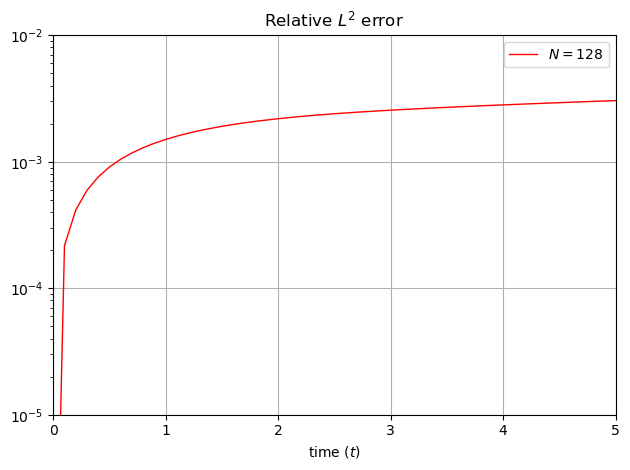

In [15]:
torch.save(rel_errors[K__RFNO_PARAM].mean(dim=0), f"rfno_param_rel_error__res{RESOLUTION}.pth")

plt.title(rf"Relative $L^{int(METRIC_ORDER)}$ error")
plt.plot(arr_t, rel_errors[K__RFNO_PARAM].mean(dim=0), linewidth=1, color='red', label=rf"$N={RESOLUTION}$")
plt.yscale('log')
plt.xlabel(r'time ($t$)')
plt.xlim((arr_t.min(), arr_t.max()))
plt.ylim((1e-5, 1e-2))
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()